# PharmaCorp's four answers + ad-hoc queries

Steps through Q1-Q4 the same way `python src/analysis.py` does, then a few ad-hoc
queries beyond those four (bonus, from `src/queries.py`) -- every cell below calls
the actual `analysis.py`/`queries.py` functions, nothing here is recomputed inline.
Each section shows its own chart right where the answer is, only where a chart
actually adds something over the printed numbers (Q2's barrier mix or Q4's step
histogram are worth a picture; a single churn-rate number isn't).

Evaluation (golden-set accuracy, LLM-as-judge) lives in `notebooks/02_evaluation.ipynb`.


## Setup

In [1]:
import os
# This notebook lives in notebooks/ but all paths (data/, src/) are repo-root-
# relative -- hop up one level if launched from inside notebooks/, no-op otherwise.
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

import sys
from pathlib import Path
sys.path.insert(0, 'src')
import analysis
import queries

try:
    from IPython.display import Image, display
    def show_chart(path):
        display(Image(filename=str(path)))
except ImportError:
    def show_chart(path):
        print(f'(not running in Jupyter/IPython -- open {path} directly)')

records = analysis.load_records()
patients, treatments, encounters = queries.to_frames(records)
print(f'{len(records)} records loaded')


50 records loaded


## Q1 · What fraction of patients are on a biologic?

`analysis.q1_on_biologic` reports a point estimate plus a stated-only .. could-still-be-on
band, and a secondary confidence-weighted estimate (see the design-decisions section for
why the band, not the single point estimate, is the primary number).

point estimate: 74%  (on=37, off=13, unknown=0)
band (stated-only .. everything that could still be on): 74%-74%
confidence-weighted estimate (secondary): 74%


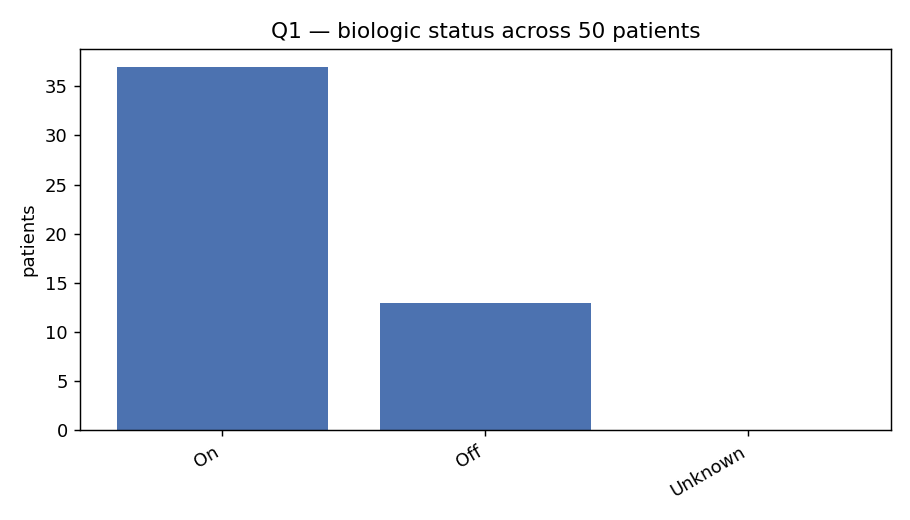

In [2]:
q1 = analysis.q1_on_biologic(records)
print(f"point estimate: {q1['pct_on_point_estimate']:.0%}  "
      f"(on={q1['on']}, off={q1['off']}, unknown={q1['unknown']})")
print(f"band (stated-only .. everything that could still be on): "
      f"{q1['band_low']:.0%}-{q1['band_high']:.0%}")
cwe = q1['band_detail'].get('confidence_weighted_estimate')
if cwe is not None:
    print(f"confidence-weighted estimate (secondary): {cwe:.0%}")

path = analysis.CHART_DIR / 'q1_biologic_status.png'
analysis._bar_chart(['On', 'Off', 'Unknown'], [q1['on'], q1['off'], q1['unknown']],
                     'Q1 — biologic status across 50 patients', 'patients', path)
show_chart(path)


## Q2 · Why aren't the rest on one?

Only defined for patients not confirmed on a biologic (`on_biologic in (False, None)`) --
scored as a set of barrier types, since a patient can have more than one reason.

of 13 not confirmed on a biologic:
  cost_insurance       6
  step_therapy         6
  comorbidity_risk     5
  patient_fear         4
  surgery_first        1
no reason identified: 1 (of which churned before it surfaced: 0)


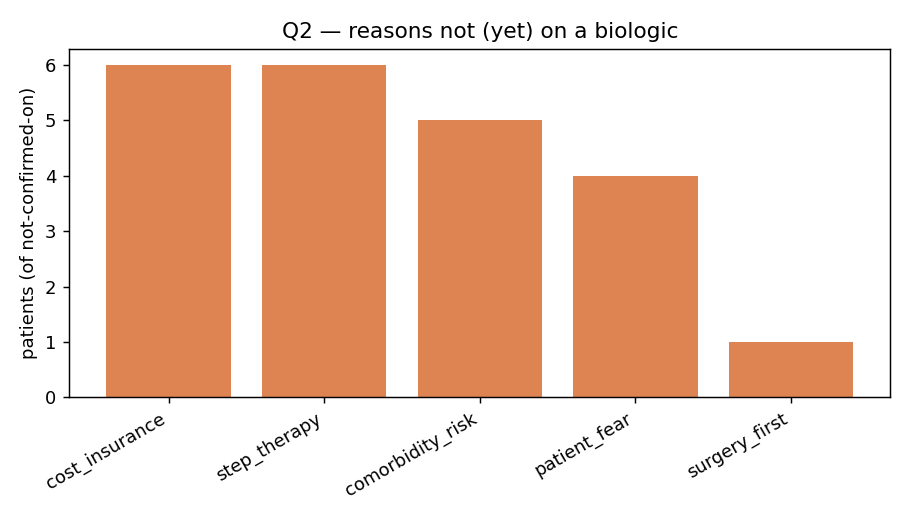

In [3]:
q2 = analysis.q2_barriers(records)
print(f"of {q2['denominator_n']} not confirmed on a biologic:")
for k, v in sorted(q2['barrier_counts'].items(), key=lambda x: -x[1]):
    print(f'  {k:20} {v}')
print(f"no reason identified: {q2['no_barrier_identified']} "
      f"(of which churned before it surfaced: {q2['of_which_churned_before_known']})")

if q2['barrier_counts']:
    items = sorted(q2['barrier_counts'].items(), key=lambda x: -x[1])
    path = analysis.CHART_DIR / 'q2_barrier_frequency.png'
    analysis._bar_chart([k for k, _ in items], [v for _, v in items],
                         'Q2 — reasons not (yet) on a biologic', 'patients (of not-confirmed-on)',
                         path, color='#DD8452')
    show_chart(path)


## Q3 · What do patients try first?

Treatment classes tried/discussed before a biologic, across all 50 -- an empty sequence
is itself an answer (some patients go straight to a biologic).

of 50 patients:
  aminosalicylate      41
  corticosteroid       36
  immunomodulator      31
  other                6
  antibiotic           1
none tried first (straight to biologic or never got there): 2


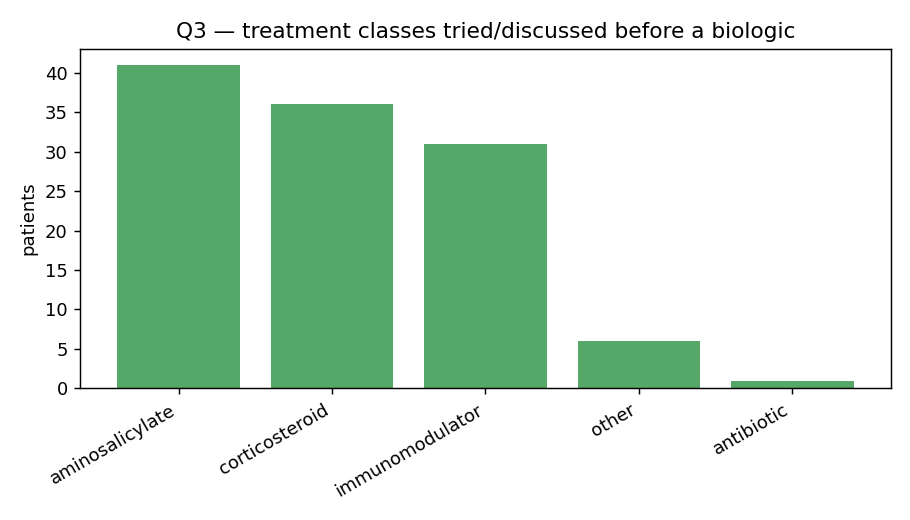

In [4]:
q3 = analysis.q3_treatments_before_biologic(records)
print(f"of {q3['n']} patients:")
for k, v in sorted(q3['class_counts'].items(), key=lambda x: -x[1]):
    print(f'  {k:20} {v}')
print(f"none tried first (straight to biologic or never got there): {q3['none_tried_first']}")

if q3['class_counts']:
    items = sorted(q3['class_counts'].items(), key=lambda x: -x[1])
    path = analysis.CHART_DIR / 'q3_treatment_class_frequency.png'
    analysis._bar_chart([k for k, _ in items], [v for _, v in items],
                         'Q3 — treatment classes tried/discussed before a biologic', 'patients',
                         path, color='#55A868')
    show_chart(path)


## Q4 · How many referral steps to get there?

Only counts patients whose referral chain actually resolved (a biologic was prescribed
or discussed) -- churned patients who never got that far are reported separately as
"not assessable", not coded as 0 steps.

resolved for 49/50; 1 not assessable
  1 steps: 10 patients
  2 steps: 34 patients
  3 steps: 5 patients
mean: 1.9 steps
entry points: {'gp_pcp': 28, 'other_specialist': 4, 'er': 7, 'gi_specialist': 9, 'surgeon': 1}


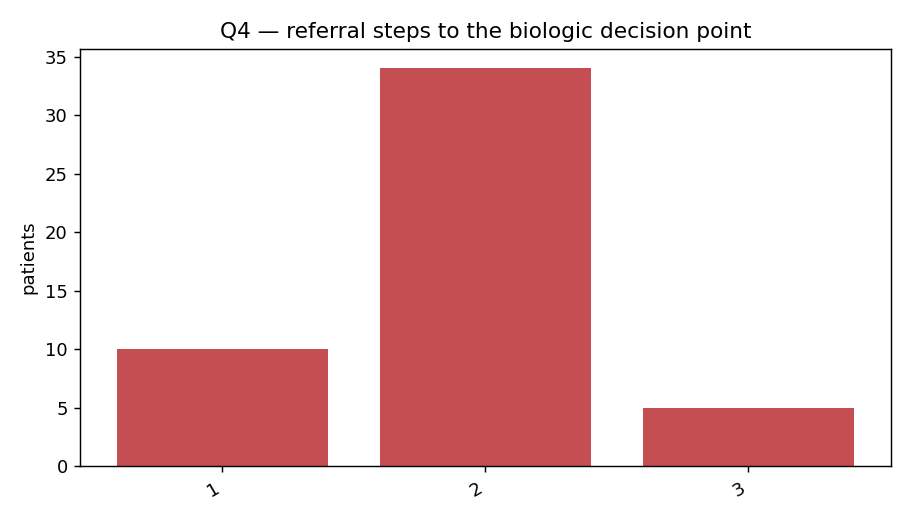

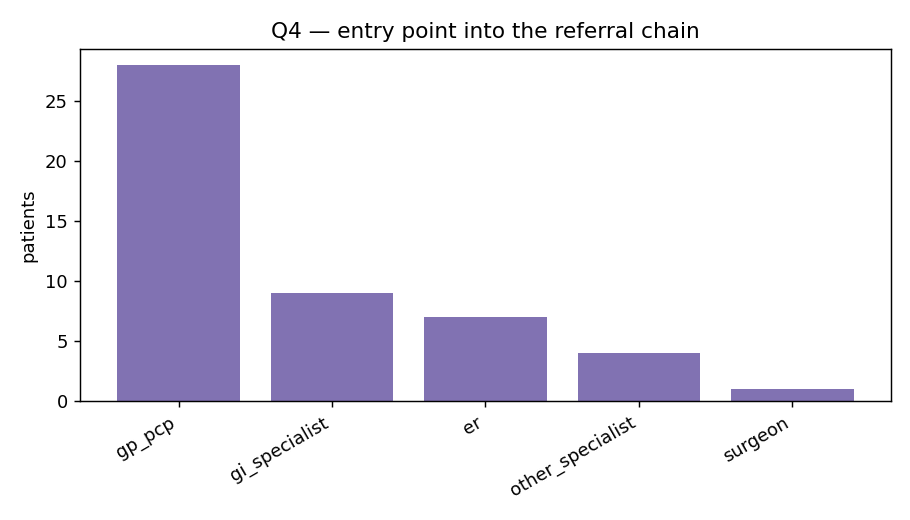

In [5]:
q4 = analysis.q4_referral_steps(records)
print(f"resolved for {q4['n_resolved']}/{len(records)}; "
      f"{q4['not_assessable_n']} not assessable")
for k, v in sorted(q4['step_counts'].items()):
    print(f'  {k} steps: {v} patients')
if q4['mean_steps'] is not None:
    print(f"mean: {q4['mean_steps']:.1f} steps")
print('entry points:', q4['entry_point_mix'])

if q4['step_counts']:
    items = sorted(q4['step_counts'].items())
    path = analysis.CHART_DIR / 'q4_step_histogram.png'
    analysis._bar_chart([str(k) for k, _ in items], [v for _, v in items],
                         'Q4 — referral steps to the biologic decision point', 'patients',
                         path, color='#C44E52')
    show_chart(path)

if q4['entry_point_mix']:
    items = sorted(q4['entry_point_mix'].items(), key=lambda x: -x[1])
    path = analysis.CHART_DIR / 'q4_entry_point_mix.png'
    analysis._bar_chart([k for k, _ in items], [v for _, v in items],
                         'Q4 — entry point into the referral chain', 'patients',
                         path, color='#8172B2')
    show_chart(path)


## Churn — how much of the above is capped by truncated interviews

In [6]:
churn = analysis.churn_summary(records)
print(f"churned/truncated: {churn['churned']}/{churn['n']} ({churn['churn_rate']:.0%})")


churned/truncated: 3/50 (6%)


## Ad-hoc queries (bonus, beyond the required four)

Three worked examples of the kind of open-ended question the structured output
makes answerable -- proof the schema is *usable*, not just built to answer exactly
four fixed questions. Each one shows its chart right below it, same as Q1-Q4 above.


### Of people who tried mesalamine, how many found it useful?


Q) Of people who tried "mesalamine", how many found it useful?
   tried: 40  |  outcome known: 40  |  useful (effective/partial): 9
patient_id                          name_raw          outcome
      P001                        mesalamine      ineffective
      P002                        mesalamine      ineffective
      P003                        mesalamine      ineffective
      P004                        mesalamine      ineffective
      P005                        mesalamine          partial
      P008                        mesalamine      ineffective
      P009                        mesalamine      ineffective
      P010                        mesalamine      ineffective
      P011                        mesalamine      ineffective
      P012                        mesalamine      ineffective
      P013                        Mesalamine          partial
      P015                        mesalamine      ineffective
      P016                        mesalamine      ineffective

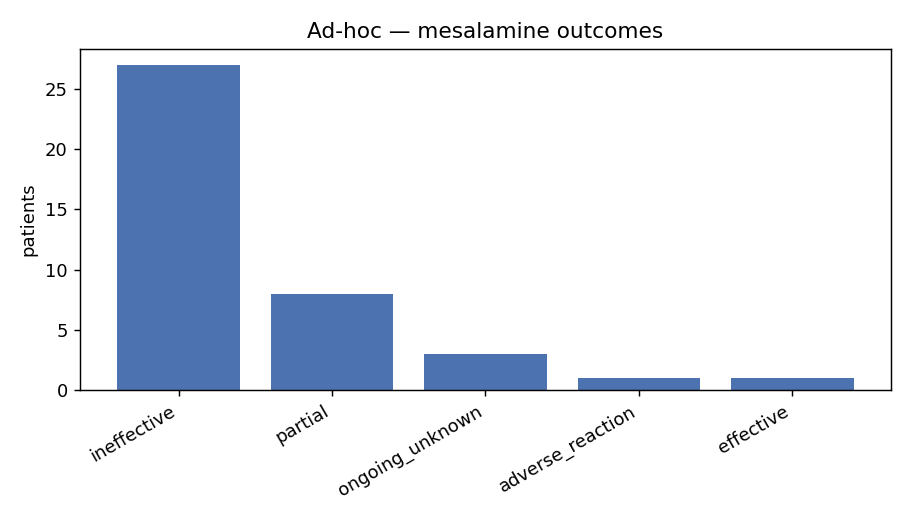

In [7]:
mesalamine = queries.q_drug_usefulness(treatments, 'mesalamine')
outcome_counts = mesalamine['outcome'].value_counts()
if not outcome_counts.empty:
    path = analysis.CHART_DIR / 'adhoc_mesalamine_outcomes.png'
    analysis._bar_chart(list(outcome_counts.index), list(outcome_counts.values),
                         'Ad-hoc — mesalamine outcomes', 'patients', path, color='#4C72B0')
    show_chart(path)


### Among patients with diarrhea, which treatment class had the best outcomes?


Q) Among patients with "diarrhea", which class had the best outcomes?
                 useful_rate   n
drug_class                      
corticosteroid          0.83  24
biologic                0.60  42
other                   0.40   5
immunomodulator         0.25  32
aminosalicylate         0.17  30


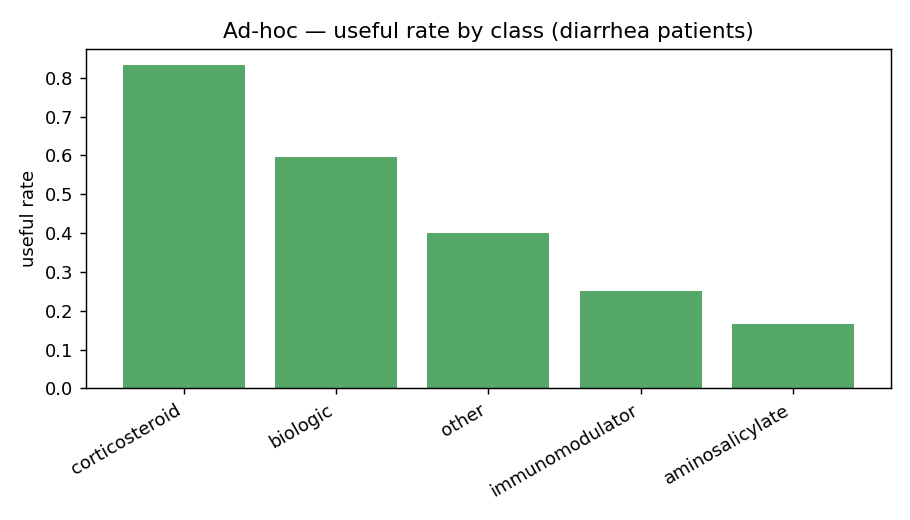

In [8]:
diarrhea_tbl = queries.q_best_treatment_for_symptom(patients, treatments, 'diarrhea')
if diarrhea_tbl is not None and not diarrhea_tbl.empty:
    path = analysis.CHART_DIR / 'adhoc_diarrhea_useful_rate.png'
    analysis._bar_chart(list(diarrhea_tbl.index), list(diarrhea_tbl['useful_rate']),
                         'Ad-hoc — useful rate by class (diarrhea patients)', 'useful rate',
                         path, color='#55A868')
    show_chart(path)


### Of patients diagnosed more than 5 years ago, what's the disease-control breakdown?


Q) Of patients diagnosed > 5 years ago, disease control breakdown:
disease_control
partial      17
poor          2
remission     1
patient_id  years_since_dx disease_control
      P001             8.0       remission
      P003            12.0         partial
      P006            10.0         partial
      P008             8.0         partial
      P011             7.0         partial
      P013             8.0         partial
      P015            15.0         partial
      P020             7.0         partial
      P026             8.0            poor
      P028             6.0         partial
      P029            12.0         partial
      P031            15.0         partial
      P033             7.0         partial
      P035            14.0         partial
      P037             6.0         partial
      P038            10.0            poor
      P039             8.0         partial
      P040             7.0         partial
      P041             7.0         partial
      P0

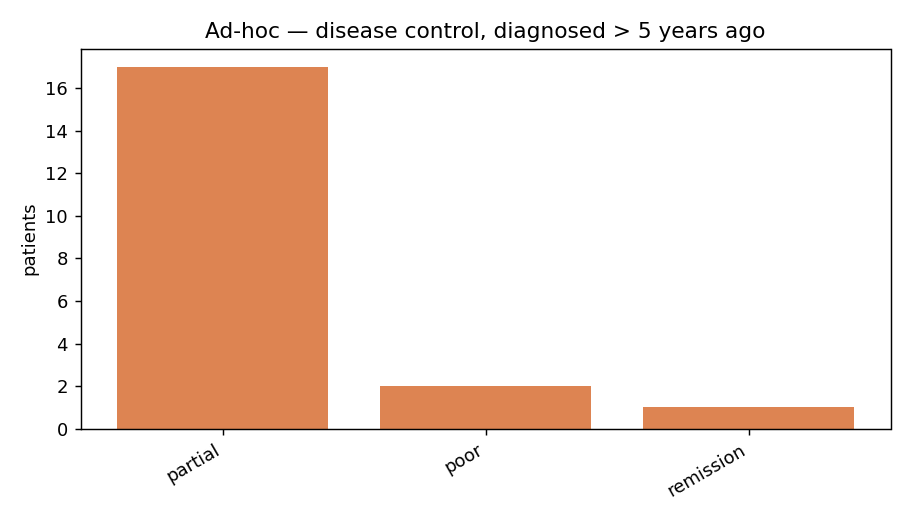

In [9]:
tenure = queries.q_remission_by_tenure(patients, 5)
if not tenure.empty:
    dc_counts = tenure['disease_control'].value_counts()
    path = analysis.CHART_DIR / 'adhoc_remission_by_tenure.png'
    analysis._bar_chart(list(dc_counts.index), list(dc_counts.values),
                         'Ad-hoc — disease control, diagnosed > 5 years ago', 'patients',
                         path, color='#DD8452')
    show_chart(path)


---

Narrative writeup of these numbers (what they mean, caveats, comparison across model
runs) lives in the README's Analysis section — this notebook is the reproducible
source of both the required numbers and the ad-hoc query results, charts included.
